In [1]:
# For this assignment, use the ERA-5 *monthly mean* data at NCAR (DOI: 10.5065/P8GT-0R61) as we did in Module 2.  
# Feel free to reduce the data to 1 degree resolution if you need to save data download times.

In [2]:
import numpy as np
import xarray as xr

In [3]:
# 1) Create a dataset that contains the monthly means of Sea Surface Temperature anomalies and total column water vapor (tcrw is used below, so using 'total column rain water' variable)
# from Jan 1979-Dec 2024 over the Pacific Basin (65°N to 65°S, 120°E to 60°W) masked out over land - save this to your computer. 
# The data and land sea mask is available here: 
# [https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download]

In [4]:
# Open the netcdf dataset that has been downloaded and saved in this folder:

sst_tcrw = xr.open_dataset('sst_tcwv_pacific_data.nc', engine='h5netcdf')

In [5]:
# Read the dataset to check dims, coords, and variables

sst_tcrw

<xarray.Dataset> Size: 5GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 1440)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
    expver      (valid_time) <U4 9kB ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 2GB ...
    tcrw        (valid_time, latitude, longitude) float32 2GB ...
    lsm         (valid_time, latitude, longitude) float32 2GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-21T18:04 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
# Looking at dataset:
# Dates are correct (Jan 1979 - Dec 2024
# Lat is correct (65 to -65)
# Lon is -180 to 180. Need to slice this to 120 E to 60 W!
# Data variables: sst, tcrw, and lsm (land sea map)

In [7]:
# 120 E to 60 W crosses the date line, so it might be easier to convert these to 0-360 before slicing
sst_tcrw_360 = sst_tcrw.assign_coords(
    longitude=(((sst_tcrw.longitude + 360) % 360))
)
sst_tcrw_360 = sst_tcrw_360.sortby('longitude')

In [8]:
sst_tcrw_360

<xarray.Dataset> Size: 5GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 1440)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
    expver      (valid_time) <U4 9kB ...
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Data variables:
    sst         (valid_time, latitude, longitude) float32 2GB ...
    tcrw        (valid_time, latitude, longitude) float32 2GB ...
    lsm         (valid_time, latitude, longitude) float32 2GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-21T18:04 GRIB to CDM+CF via cfgrib-0.9.1...

In [9]:
# Now slice for 120 E to 60 W
sst_tcrw_slice = sst_tcrw_360.sel(longitude=slice(120, 300))
sst_tcrw_slice = sst_tcrw_slice.transpose('valid_time', 'latitude', 'longitude')

sst_tcrw_slice

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
    expver      (valid_time) <U4 9kB ...
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB ...
    tcrw        (valid_time, latitude, longitude) float32 829MB ...
    lsm         (valid_time, latitude, longitude) float32 829MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-21T18:04 GRIB to CDM+CF via cfgrib-0.9.1...

In [10]:
# 2) From the dataset shown in 1, compute anomalies by deseasonalizing the data (remove the mean monthly anomaly from the annual mean from each point) and detrend the data. 


def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    # numeric seconds since first timestamp (keeps numbers small)
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj[time_dim], time_dim)  # (time,)
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})  # one chunk along time
        mask = da.notnull()                                # (time, ...)
        t_b = t.broadcast_like(da)                         # (time, ...)
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True)
        tc = t_b - t_mean_valid                            # centered time per point
        num = (da * tc).sum(time_dim, skipna=True)
        den = (tc**2).sum(time_dim, skipna=True)
        slope = xr.where(den > 0, num / den, 0.0)
        ybar  = da.mean(time_dim, skipna=True)
        trend = slope * (t_b - t_mean_valid) + ybar
        return (da - trend).astype("float32")
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj)

def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True)
    anom = detr.groupby(key) - clim_mean

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)
    z = anom.groupby(key) / safe_std
    return anom, z


# Example:
# ds is a monthly ERA5 Dataset or DataArray with dimension "time" - changed 'ds' to 'sst_tcrw_slice' to match my dataset's name
# If Dataset, all variables get processed; if DataArray, just that variable
# ds = ds.chunk({"time": -1})  # optional: ensure time is a single chunk for speed
# Optional: keep time in one chunk for speed
sst_tcrw_slice = sst_tcrw_slice.chunk({"valid_time": -1})

detr = linear_detrend(sst_tcrw_slice[["sst", "tcrw"]], time_dim="valid_time")   # or just ds if you want all float vars
anom, z = monthly_anom_and_z(detr, time_dim="valid_time",
                             base_period=("1981-01-01", "2010-12-31"))  # or None for full-period

print(type(z), list(z.data_vars))   # should show a Dataset with ['sst','tcrw']


<class 'xarray.core.dataset.Dataset'> ['sst', 'tcrw']


/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [11]:
print(anom)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>
    tcrw        (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>


In [12]:
print(z)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>
    tcrw        (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(1, 521, 721), meta=np.ndarray>


In [13]:
print(detr)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>
    tcrw        (valid_time, latitude, longitude) float32 829MB dask.array<chunksize=(552, 521, 721), meta=np.ndarray>


In [14]:
# 3) Perform an EOF analysis on the SST anomalies and plot a map of the first 5 EOFs, following M04N05.

In [15]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from eofs.xarray import Eof
from eofs.examples import example_data_path

In [16]:
#Convert the dataset of detrended anomalies to a data array
detr_sst = detr['sst']
detr_sst

<xarray.DataArray 'sst' (valid_time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<astype, shape=(552, 521, 721), dtype=float32, chunksize=(552, 521, 721), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0

In [17]:
# Eofs requires time to be the first dimension and suggested using the transpose() method
# It is already in the first dimension, so the issue may be that it doesn't recognize 'valid_time' - will rename this to 'time'
detr_sst = detr_sst.rename({'valid_time': 'time'})
detr_sst

<xarray.DataArray 'sst' (time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<astype, shape=(552, 521, 721), dtype=float32, chunksize=(552, 521, 721), chunktype=numpy.ndarray>
Coordinates:
    number     int64 8B 0
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
    expver     (time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001' '0001'
  * longitude  (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0

In [ ]:
# Create an EOF solver to do the EOF analysis. Square-root of cosine of latitude weights are applied before the computation of EOFs.
coslat = np.cos(np.deg2rad(detr_sst.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(detr_sst, weights=wgts)


/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [19]:
# Retrieve the first 5 EOFs, and plot them on a map
eof1 = solver.eofsAsCorrelation(neofs=5)
pc1 = solver.pcs(npcs=5, pcscaling=1)


/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


Text(0.5, 1.0, 'EOF1 expressed as correlation')

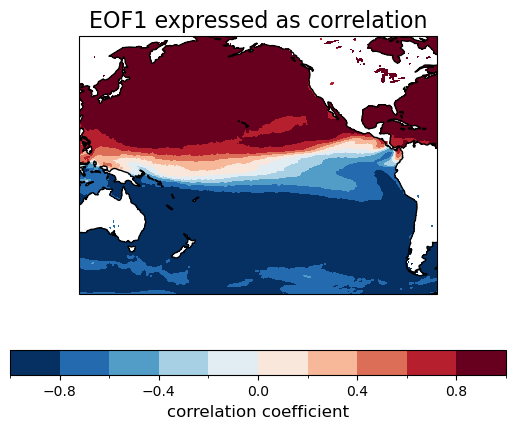

In [20]:
# Plot EOF 1

clevs = np.linspace(-1, 1, 11)
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = eof1[0].plot.contourf(ax=ax, levels=clevs, cmap=plt.cm.RdBu_r,
                             add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('EOF1 expressed as correlation', fontsize=16)

/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


Text(0.5, 1.0, 'EOF2 expressed as correlation')

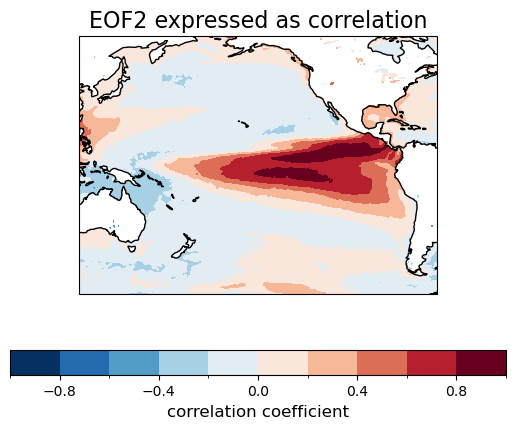

In [21]:
# Plot EOF 2

clevs = np.linspace(-1, 1, 11)
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = eof1[1].plot.contourf(ax=ax, levels=clevs, cmap=plt.cm.RdBu_r,
                             add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('EOF2 expressed as correlation', fontsize=16)

/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


Text(0.5, 1.0, 'EOF3 expressed as correlation')

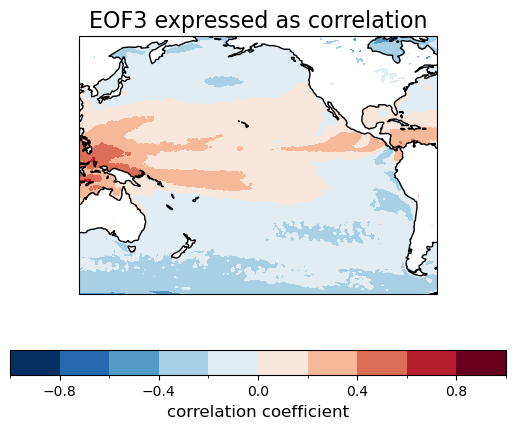

In [22]:
# Plot EOF 3

clevs = np.linspace(-1, 1, 11)
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = eof1[2].plot.contourf(ax=ax, levels=clevs, cmap=plt.cm.RdBu_r,
                             add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('EOF3 expressed as correlation', fontsize=16)

/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


Text(0.5, 1.0, 'EOF4 expressed as correlation')

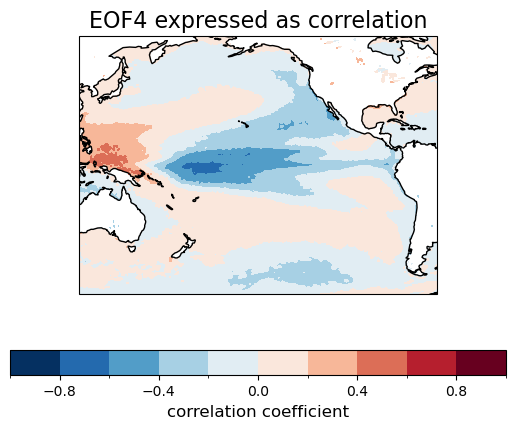

In [23]:
# Plot EOF 4

clevs = np.linspace(-1, 1, 11)
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = eof1[3].plot.contourf(ax=ax, levels=clevs, cmap=plt.cm.RdBu_r,
                             add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('EOF4 expressed as correlation', fontsize=16)

/home/hildebr1/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


Text(0.5, 1.0, 'EOF5 expressed as correlation')

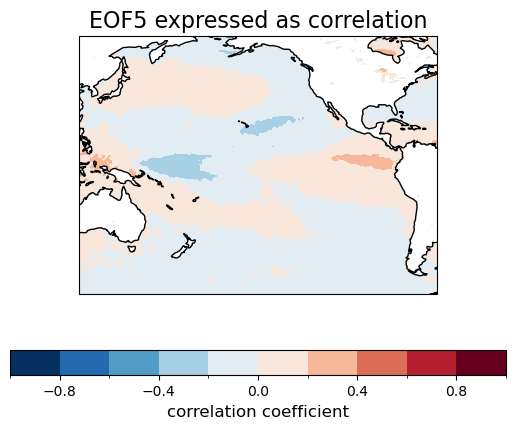

In [24]:
# Plot EOF 5

clevs = np.linspace(-1, 1, 11)
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = eof1[4].plot.contourf(ax=ax, levels=clevs, cmap=plt.cm.RdBu_r,
                             add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('EOF5 expressed as correlation', fontsize=16)

In [25]:
# 4) Plot the percent of variance explained by the first 10 EOFs.

In [26]:
# Run the variance fraction over a range
varfrac = solver.varianceFraction()

(4.476634059917063e-18, 0.8589237928390503)

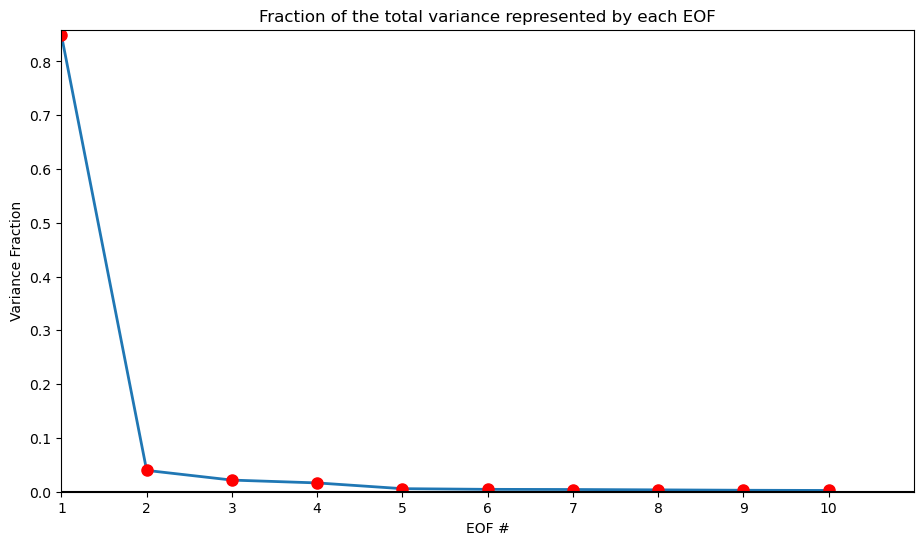

In [27]:
# Plot the fraction of variance explained by each EOF
plt.figure(figsize=(11,6))
eof_num = range(1, 11)
plt.plot(eof_num, varfrac[0:10], linewidth=2)
plt.plot(eof_num, varfrac[0:10], linestyle='None', marker="o", color='r', markersize=8)
plt.axhline(0, color='k')
plt.xticks(range(1, 11))
plt.title('Fraction of the total variance represented by each EOF')
plt.xlabel('EOF #')
plt.ylabel('Variance Fraction')
plt.xlim(1, 11)
plt.ylim(np.min(varfrac), np.max(varfrac)+0.01)

In [28]:
# The first EOF explains over 80% of the variance in the map of SSTs - pattern could be used to represent a lot of the variability. 
# The 2nd through 10th are not so good.
# North's rule of thumb - would probably only include the 1st EOF.

In [29]:
# 5) Reconstruct the SST field using the first 5 EOFs and plot a map of the Pearson's correlation coefficient 
# ([xarray.corr](https://docs.xarray.dev/en/stable/generated/xarray.corr.html)) 
# of the reconstructed monthly time series and the "observed" SST time series.

reconstruction = solver.reconstructedField(5)
reconstruction

<xarray.DataArray 'sst' (time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<divide, shape=(552, 521, 721), dtype=float32, chunksize=(552, 521, 721), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver     (time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001' '0001'
Attributes:
    long_name:  sst_reconstructed_with_5_EOFs

In [30]:

sst_corr = xr.corr(reconstruction, detr_sst, dim='time')

In [ ]:
proj = ccrs.PlateCarree(central_longitude=180)

plt.figure(figsize=(10,5))
ax = plt.axes(projection=proj)

# Plot correlation map
im = sst_corr.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',
    vmin=-1, vmax=1,        
    cbar_kwargs={'label': 'Correlation'}
)

ax.coastlines()
ax.set_extent([120, 300, -65, 65], crs=ccrs.PlateCarree())
plt.title('Pearsons Correlation Coefficient of Reconstructed and Observed SST')
plt.show()

In [ ]:
# 6) Compute a map of the Pearson's correlation coefficient between SST EOF1 and monthly mean detrended, deseasonalized, and standardized monthly mean column water vapor anomalies 
# (don't mask these over land for the plot).  See anything interesting?

In [ ]:
#Convert the dataset of detrended anomalies to a data array
detr_tcrw = detr['tcrw']
detr_tcrw

In [ ]:

# Run reconstruction again, but only for EOF1 instead of leading 5

reconstruction_EOF1 = solver.reconstructedField(1)
reconstruction_EOF1

In [ ]:
# Compute Pearson's correlation coefficient for this reconstruction

sst_corr_EOF1 = xr.corr(reconstruction_EOF1, detr_tcrw, dim='time')

In [ ]:
proj = ccrs.PlateCarree(central_longitude=180)

plt.figure(figsize=(10,5))
ax = plt.axes(projection=proj)

# Plot correlation map
im = sst_corr_EOF1.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',
    vmin=-1, vmax=1,        
    cbar_kwargs={'label': 'Correlation'}
)

ax.set_extent([120, 300, -65, 65], crs=ccrs.PlateCarree())
plt.title('Pearsons Correlation Coefficient of Reconstructed and Observed TCRW')
plt.show()